# Self-Organizing Maps (SOM) dan pembelajaran tak terawasi
## Perhitungan manual dan praktik NumPy
Mata kuliah Jaringan Syaraf Tiruan, FTI UKDW. Notebook ini memakai SOM online dengan neighborhood (ketetanggaan) Gaussian. Jalankan sel dari atas ke bawah melalui **Run All Cells**. Kebutuhan: Python 3, NumPy, dan Matplotlib. Tidak memerlukan unduhan dataset atau pustaka SOM tambahan.

Contoh A memakai 2 fitur dan peta 1 × 3. Contoh B memakai 180 data sintetis dengan 4 fitur dan peta 6 × 6. Data sintetis menggambarkan skor aktivitas permainan dan tidak berasal dari mahasiswa atau pemain nyata.

**Konvensi:** koordinat Python dimulai dari 0. Neuron N1, N2, N3 pada buku berpadanan dengan indeks 0, 1, 2. Angka cetak dibulatkan, tetapi perhitungan menggunakan presisi penuh.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Contoh menggunakan seed tetap dan operasi NumPy.")

Python: 3.12.14
NumPy: 2.3.5
Contoh menggunakan seed tetap dan operasi NumPy.


## A1 Data dan bobot awal untuk hitungan manual
Masukan pertama x = [0.2, 0.8]. Posisi peta r = [0, 1, 2] terpisah dari bobot w yang masing-masing mempunyai dua komponen. Gunakan alpha = 0.5 dan sigma = 1.0. Tidak ada target kelas atau bias dalam model ini.

In [2]:
x = np.array([0.2, 0.8])
W0 = np.array([[0.1, 0.2], [0.4, 0.7], [0.8, 0.9]])
r = np.arange(3, dtype=float)
alpha, sigma = 0.5, 1.0
print("x =", x)
print("W0 =\n", W0)
print("Posisi peta =", r)

x = [0.2 0.8]
W0 =
 [[0.1 0.2]
 [0.4 0.7]
 [0.8 0.9]]
Posisi peta = [0. 1. 2.]


## A2 Jarak dan BMU
Hitung D_j = jumlah kuadrat selisih fitur. BMU adalah neuron dengan D_j terkecil. Menggunakan akar kuadrat menghasilkan pemenang yang sama. Jika terjadi nilai minimum yang sama, contoh kode memilih indeks pertama.

In [3]:
D = ((W0 - x) ** 2).sum(axis=1)
c = int(np.argmin(D))
print("Jarak kuadrat =", D)
print("Jarak Euclidean =", np.sqrt(D))
print("BMU = N", c + 1, "(indeks Python", c, ")")
assert np.allclose(D, [0.37, 0.05, 0.37])
assert c == 1

Jarak kuadrat = [0.37 0.05 0.37]
Jarak Euclidean = [0.608276 0.223607 0.608276]
BMU = N 2 (indeks Python 1 )


## A3 Fungsi tetangga dan pembaruan seluruh bobot
h_j = exp(-(r_j-r_c)^2 / (2 sigma^2)). Bobot baru W1 = W0 + alpha h (x-W0). Hitung semua perpindahan dari W0 yang sama. Gaussian memberi bobot pengaruh positif pada semua neuron dalam contoh ini.

In [4]:
h = np.exp(-((r - r[c]) ** 2) / (2 * sigma ** 2))
W1 = W0 + alpha * h[:, None] * (x - W0)
print("h =", h)
print("alpha * h =", alpha * h)
print("W1 =\n", W1)
expected = np.array([[0.1303265329856, 0.3819591979138],
                     [0.3, 0.75],
                     [0.6180408020862, 0.8696734670144]])
assert np.allclose(W1, expected, atol=1e-12)
assert np.all(np.linalg.norm(W1 - x, axis=1) < np.linalg.norm(W0 - x, axis=1))

h = [0.606531 1.       0.606531]
alpha * h = [0.303265 0.5      0.303265]
W1 =
 [[0.130327 0.381959]
 [0.3      0.75    ]
 [0.618041 0.869673]]


## A4 Masukan kedua memakai bobot yang sudah diperbarui
Gunakan xB = [0.9, 0.2] dengan alpha dan sigma yang masih tetap. Ini demonstrasi dua update, sehingga jadwal peluruhan belum diterapkan. Untuk update kedua, hitung ulang BMU menggunakan W1.

In [5]:
xB = np.array([0.9, 0.2])
DB = ((W1 - xB) ** 2).sum(axis=1)
cB = int(np.argmin(DB))
hB = np.exp(-((r - r[cB]) ** 2) / (2 * sigma ** 2))
W2 = W1 + alpha * hB[:, None] * (xB - W1)
print("Jarak kuadrat kedua =", DB)
print("BMU kedua = N", cB + 1)
print("h kedua =", hB)
print("W2 =\n", W2)
assert cB == 2
assert np.isfinite(W2).all()

Jarak kuadrat kedua = [0.625506 0.6625   0.527964]
BMU kedua = N 3
h kedua = [0.135335 0.606531 1.      ]
W2 =
 [[0.182409 0.369646]
 [0.481959 0.583204]
 [0.75902  0.534837]]


## A5 Visualisasi perpindahan bobot dalam ruang fitur
Titik merupakan vektor bobot, bukan posisi neuron pada grid. Garis menghubungkan bobot sebelum dan sesudah update pertama. Posisi peta N1-N2-N3 tetap selama pembelajaran.

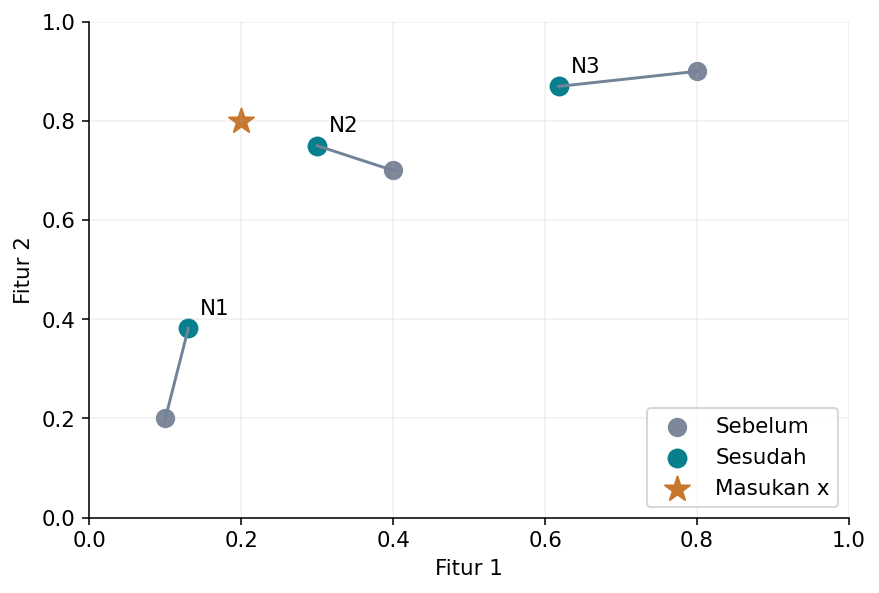

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(W0[:, 0], W0[:, 1], s=80, c="#7C879A", label="Sebelum")
ax.scatter(W1[:, 0], W1[:, 1], s=85, c="#087F8C", label="Sesudah")
ax.scatter(*x, s=180, marker="*", c="#C7762C", label="Masukan x")
for j in range(3):
    ax.plot([W0[j, 0], W1[j, 0]], [W0[j, 1], W1[j, 1]], c="#728299")
    ax.annotate(f"N{j+1}", W1[j], xytext=(6, 7), textcoords="offset points")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Fitur 1", ylabel="Fitur 2")
ax.legend(loc="lower right")
ax.grid(alpha=0.18)
plt.show()

## B1 Dataset sintetis empat fitur
Setiap baris menyatakan satu profil aktivitas permainan. Fitur: eksplorasi, interaksi sosial, tantangan, dan koleksi. Tiga pusat hanya digunakan untuk membangkitkan data simulasi. Fungsi pelatihan tidak menerima label kelompok.

Contoh ini mengeksplorasi seluruh dataset. Jika tujuannya menguji data baru, pisahkan data lebih dahulu dan hitung parameter standardisasi hanya dari data latih.

In [7]:
rng_data = np.random.default_rng(6053)
feature_names = ["Eksplorasi", "Sosial", "Tantangan", "Koleksi"]
centers = np.array([[0.2, 0.25, 0.25, 0.8],
                    [0.8, 0.25, 0.75, 0.25],
                    [0.5, 0.8, 0.5, 0.55]])
Xraw = np.vstack([rng_data.normal(loc=mu, scale=0.07, size=(60, 4))
                  for mu in centers])
Xraw = np.clip(Xraw, 0, 1)
rng_data.shuffle(Xraw)
mu = Xraw.mean(axis=0)
scale = Xraw.std(axis=0)
scale = np.where(scale == 0, 1.0, scale)
X = (Xraw - mu) / scale
print("Bentuk data:", X.shape)
print("Rata-rata asli:", mu)
print("Simpangan baku asli:", scale)
print("Rata-rata sesudah standardisasi:", X.mean(axis=0))
assert X.shape == (180, 4)
assert np.isfinite(X).all()

Bentuk data: (180, 4)
Rata-rata asli: [0.490872 0.434417 0.503632 0.540046]
Simpangan baku asli: [0.264831 0.265724 0.21618  0.233409]
Rata-rata sesudah standardisasi: [ 0. -0.  0.  0.]


## B2 Fungsi BMU dan evaluasi
QE (quantization error) adalah rata-rata jarak Euclidean ke BMU dalam ruang empat fitur yang sudah distandardisasi. TE (topographic error) adalah proporsi data dengan dua BMU terdekat yang tidak bertetangga. Kita menetapkan empat tetangga pada grid persegi: atas, bawah, kiri, kanan. Nilai QE dan TE yang lebih kecil diinginkan, tetapi keduanya mengukur aspek berbeda.

In [8]:
def map_bmu(X, W):
    flat = W.reshape(-1, X.shape[1])
    d2 = ((X[:, None, :] - flat[None, :, :]) ** 2).sum(axis=2)
    return d2.argmin(axis=1), d2

def metrics(X, W):
    winner, d2 = map_bmu(X, W)
    qe = np.sqrt(d2.min(axis=1)).mean()
    pair = np.argsort(d2, axis=1, kind="stable")[:, :2]
    p0 = np.column_stack(np.unravel_index(pair[:, 0], W.shape[:2]))
    p1 = np.column_stack(np.unravel_index(pair[:, 1], W.shape[:2]))
    adjacent = np.abs(p0 - p1).sum(axis=1) == 1
    te = np.mean(~adjacent)
    return float(qe), float(te)

## B3 Pelatihan SOM online
Alpha dan sigma meluruh secara eksponensial dari nilai awal ke nilai akhir. s = t/(T-1), dengan t sebagai indeks update dan T total update. Satu epoch mengunjungi semua 180 data sekali dalam urutan acak. Radius Gaussian sigma adalah lebar pengaruh, bukan batas keras yang menghapus tetangga di luar radius.

In [9]:
def fit_som(X, shape=(6, 6), epochs=80, alpha0=0.5, alpha_end=0.05,
            sigma0=2.5, sigma_end=0.5, seed=42):
    if epochs < 1 or np.prod(shape) < 2 or len(X) < 1:
        raise ValueError("Data dan grid harus cukup untuk pelatihan dan evaluasi.")
    if min(alpha0, alpha_end, sigma0, sigma_end) <= 0:
        raise ValueError("Alpha dan sigma harus positif.")
    rng = np.random.default_rng(seed)
    coords = np.stack(np.indices(shape), axis=-1)
    W = X[rng.integers(len(X), size=shape)].copy()
    W_initial = W.copy()
    history = [[0, *metrics(X, W)]]
    total = epochs * len(X)
    t = 0
    for epoch in range(epochs):
        for idx in rng.permutation(len(X)):
            s = t / max(total - 1, 1)
            alpha_t = alpha0 * (alpha_end / alpha0) ** s
            sigma_t = sigma0 * (sigma_end / sigma0) ** s
            x_t = X[idx]
            c = np.unravel_index(((W - x_t) ** 2).sum(axis=2).argmin(), shape)
            grid_d2 = ((coords - coords[c]) ** 2).sum(axis=2)
            h_t = np.exp(-grid_d2 / (2 * sigma_t ** 2))
            W += alpha_t * h_t[..., None] * (x_t - W)
            t += 1
        history.append([epoch + 1, *metrics(X, W)])
    return W, np.array(history), W_initial

W, history, W_initial = fit_som(X)
qe_final, te_final = metrics(X, W)
print("QE awal / akhir:", history[0, 1], qe_final)
print("TE akhir:", te_final)
print("Total update:", 80 * len(X))
assert W.shape == (6, 6, 4)
assert np.isfinite(W).all()
assert history[-1, 1] < history[0, 1]

QE awal / akhir: 0.32572986854712804 0.31197419773734614
TE akhir: 0.15555555555555556
Total update: 14400


## B4 Kurva QE dan TE
Kurva ini berasal dari data yang juga digunakan untuk pelatihan. Nilai tersebut mendeskripsikan representasi data eksplorasi, bukan estimasi akurasi pada data baru. Update SOM tidak menjamin QE turun pada setiap langkah.

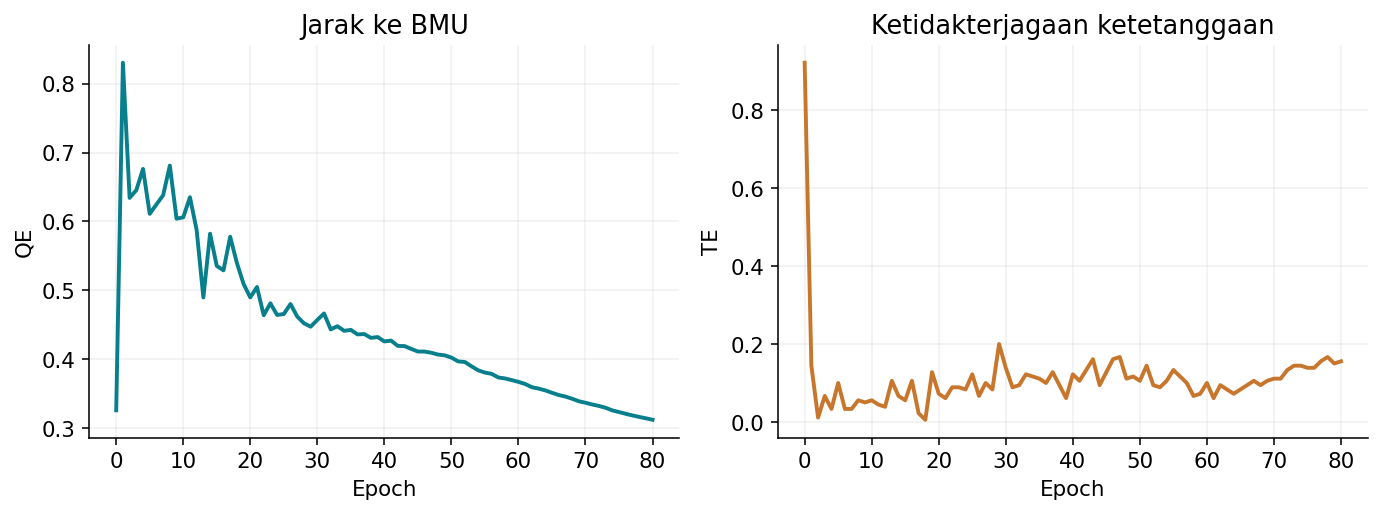

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(history[:, 0], history[:, 1], c="#087F8C", lw=2)
axes[0].set(xlabel="Epoch", ylabel="QE", title="Jarak ke BMU")
axes[1].plot(history[:, 0], history[:, 2], c="#C7762C", lw=2)
axes[1].set(xlabel="Epoch", ylabel="TE", title="Ketidakterjagaan ketetanggaan")
for ax in axes:
    ax.grid(alpha=0.18)
fig.tight_layout()
plt.show()

## B5 Hit map atau jumlah data pada setiap neuron
Isi setiap sel adalah banyaknya data yang memilih neuron tersebut sebagai BMU. Koordinat peta tidak memiliki satuan fitur. Gunakan origin="lower" agar baris 0 tampil di bawah dan orientasinya konsisten dengan grafik lain.

Jumlah data: 180
Neuron terisi: 28 dari 36


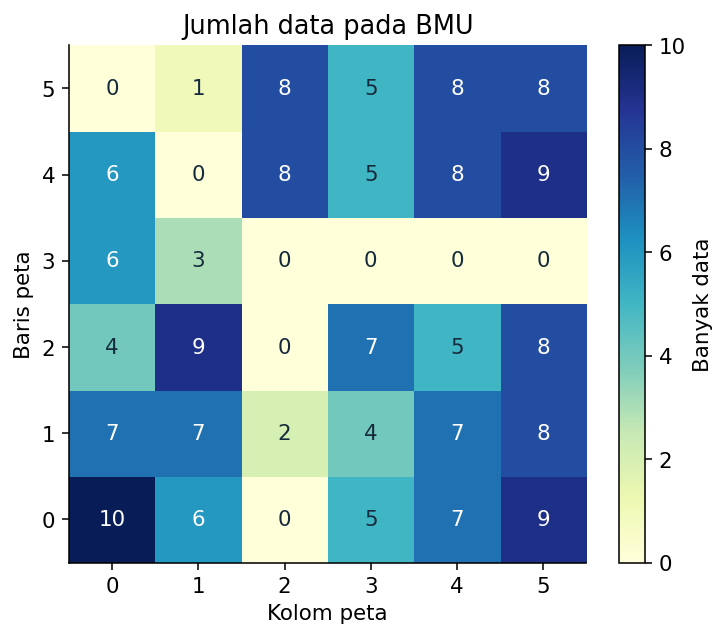

In [11]:
winner, _ = map_bmu(X, W)
hits = np.bincount(winner, minlength=36).reshape(6, 6)
print("Jumlah data:", int(hits.sum()))
print("Neuron terisi:", int((hits > 0).sum()), "dari", hits.size)
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(hits, origin="lower", cmap="YlGnBu", interpolation="nearest")
for row in range(6):
    for col in range(6):
        ax.text(col, row, str(hits[row, col]), ha="center", va="center",
                color="white" if hits[row, col] > hits.max()/2 else "#152B3D")
ax.set(xlabel="Kolom peta", ylabel="Baris peta", title="Jumlah data pada BMU")
fig.colorbar(im, ax=ax, label="Banyak data")
plt.show()
assert hits.sum() == len(X)

## B6 Component planes atau peta tiap fitur
Kembalikan bobot ke skala skor asli menggunakan Wraw = W * scale + mu. Masing-masing bidang memperlihatkan nilai satu fitur pada semua neuron. Semua bidang memakai rentang warna yang sama, 0 sampai 1.

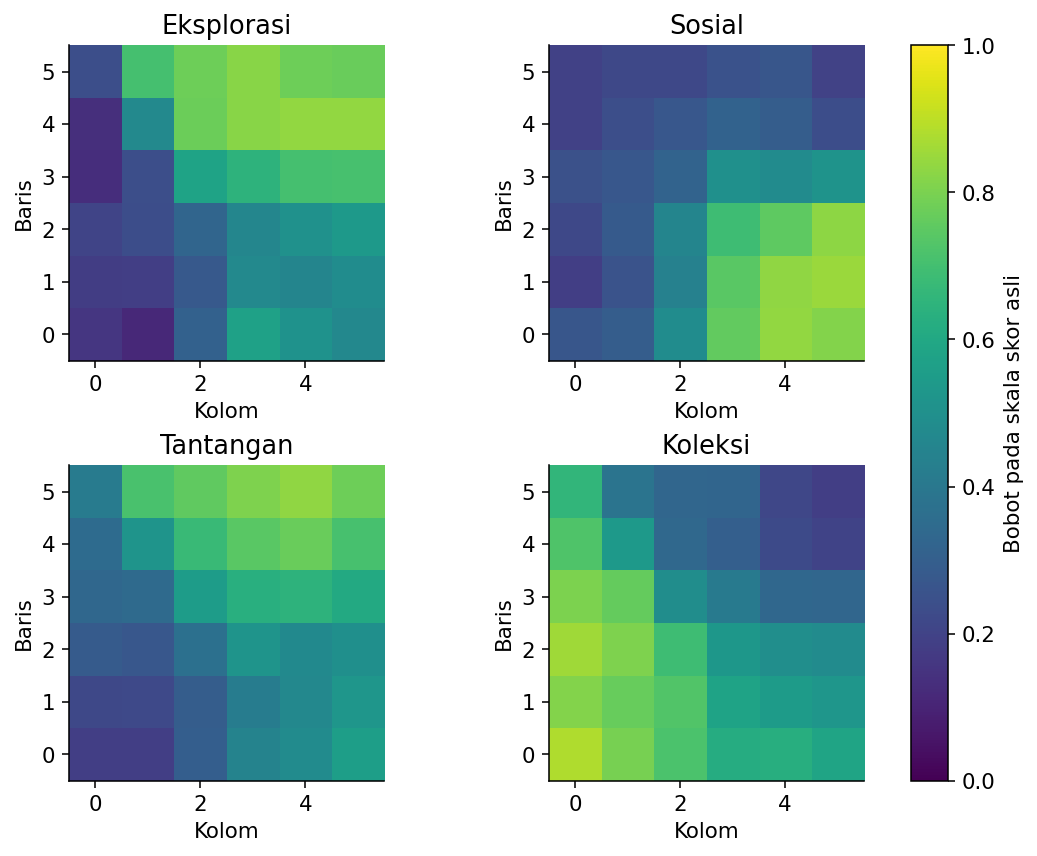

In [12]:
Wraw = W * scale + mu
fig, axes = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
for k, ax in enumerate(axes.flat):
    im = ax.imshow(Wraw[:, :, k], origin="lower", cmap="viridis",
                   vmin=0, vmax=1, interpolation="nearest")
    ax.set(title=feature_names[k], xlabel="Kolom", ylabel="Baris")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Bobot pada skala skor asli")
plt.show()

## B7 U-matrix ringkas per neuron
Implementasi ini menghitung rata-rata jarak bobot setiap neuron ke empat tetangga langsungnya. Nilai tinggi menandai perubahan prototipe yang lebih besar. Ini ringkasan per neuron, sehingga bentuknya berbeda dari U-matrix yang menempatkan jarak antarneuron di sela-sela grid. Batas warna tidak langsung menetapkan jumlah cluster.

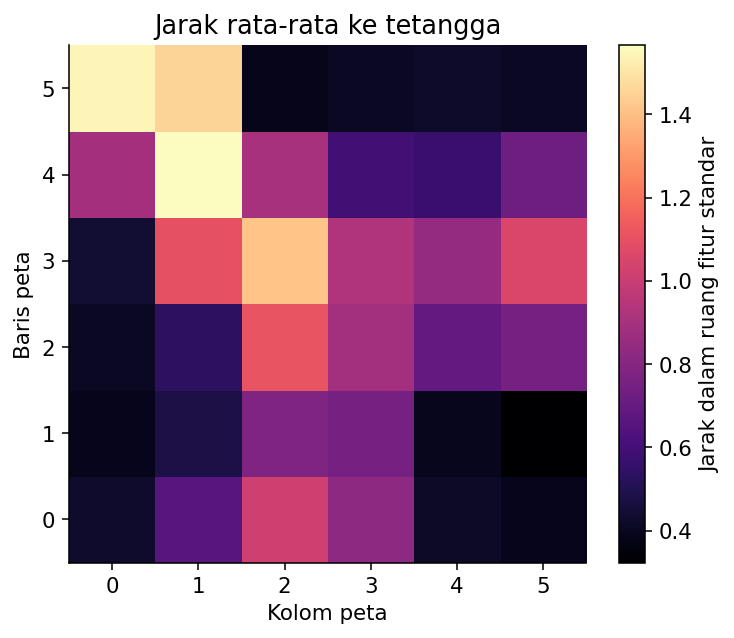

In [13]:
def u_matrix(W):
    rows, cols, _ = W.shape
    U = np.zeros((rows, cols))
    for row in range(rows):
        for col in range(cols):
            neighbors = []
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                rr, cc = row + dr, col + dc
                if 0 <= rr < rows and 0 <= cc < cols:
                    neighbors.append(np.linalg.norm(W[row, col] - W[rr, cc]))
            U[row, col] = np.mean(neighbors)
    return U

U = u_matrix(W)
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(U, origin="lower", cmap="magma", interpolation="nearest")
ax.set(xlabel="Kolom peta", ylabel="Baris peta", title="Jarak rata-rata ke tetangga")
fig.colorbar(im, ax=ax, label="Jarak dalam ruang fitur standar")
plt.show()
assert np.isfinite(U).all()

## B8 Pemetaan satu profil baru
Gunakan parameter standardisasi yang sudah dihitung dan bobot SOM yang sudah tetap. Bobot BMU adalah prototipe. ID neuron bukan label kelas. Untuk menguji generalisasi secara formal, gunakan data yang ditahan sejak awal, bukan profil buatan ini.

In [14]:
new_raw = np.array([[0.75, 0.30, 0.80, 0.20]])
new_std = (new_raw - mu) / scale
new_id, new_d2 = map_bmu(new_std, W)
new_rc = np.unravel_index(int(new_id[0]), W.shape[:2])
print("Profil baru:", new_raw[0])
print("Posisi BMU (baris, kolom):", new_rc)
print("Prototipe BMU:", Wraw[new_rc])
print("Jarak ke BMU:", float(np.sqrt(new_d2.min())))

Profil baru: [0.75 0.3  0.8  0.2 ]
Posisi BMU (baris, kolom): (np.int64(5), np.int64(4))
Prototipe BMU: [0.778721 0.268281 0.832034 0.213077]
Jarak ke BMU: 0.22606806077332658


## B9 Eksperimen terkontrol untuk sigma awal
Grid, data, seed, urutan sampling, epoch, dan alpha tetap sama. Bandingkan sigma awal 0.4, 2.5, dan 5.0 dengan sigma akhir 0.3 pada ketiganya. Bandingkan QE dan TE bersama-sama. Satu seed belum cukup untuk kesimpulan umum.

In [15]:
comparison = []
for sigma_start in [0.4, 2.5, 5.0]:
    W_try, _, _ = fit_som(X, sigma0=sigma_start, sigma_end=0.3, seed=42)
    qe, te = metrics(X, W_try)
    comparison.append([sigma_start, qe, te])
comparison = np.array(comparison)
print("sigma0       QE         TE")
for row in comparison:
    print(f"{row[0]:6.1f}   {row[1]:.6f}   {row[2]:.6f}")

sigma0       QE         TE
   0.4   0.278768   0.650000
   2.5   0.288326   0.288889
   5.0   0.289712   0.255556


## Latihan mandiri
1. Hitung satu update untuk x=[0.8,0.2], W=[[0.2,0.2],[0.6,0.4],[0.9,0.8]], alpha=0.4, sigma=1, r=[0,1,2]. Tentukan BMU, h, dan bobot baru.
2. Ubah grid menjadi 4 × 4, kemudian 8 × 8. Perbaiki ukuran visualisasi yang sebelumnya tetap 6 × 6 menggunakan W.shape[:2]. Bandingkan QE, TE, dan neuron kosong dengan setidaknya tiga seed.
3. Jelaskan satu wilayah peta menggunakan hit map dan minimal dua component planes. Hindari menyimpulkan karakter pribadi atau nilai akademik dari skor aktivitas sintetis.

**Kunci latihan 1 terdapat pada sel berikut. Jalankan setelah menyelesaikan hitungan.**

In [16]:
x_task = np.array([0.8, 0.2])
W_task = np.array([[0.2, 0.2], [0.6, 0.4], [0.9, 0.8]])
D_task = ((W_task - x_task)**2).sum(axis=1)
c_task = int(D_task.argmin())
h_task = np.exp(-((r-r[c_task])**2)/2)
W_task_new = W_task + 0.4*h_task[:, None]*(x_task-W_task)
print("D latihan =", D_task)
print("BMU latihan = N", c_task+1)
print("Bobot baru =\n", W_task_new)
assert c_task == 1
assert np.allclose(W_task_new, [[0.345567358331,0.2],
                              [0.68,0.32],
                              [0.875738773611,0.654432641669]], atol=1e-12)

D latihan = [0.36 0.08 0.37]
BMU latihan = N 2
Bobot baru =
 [[0.345567 0.2     ]
 [0.68     0.32    ]
 [0.875739 0.654433]]


## Referensi
- Kohonen, T. (1982). Self-organized formation of topologically correct feature maps. *Biological Cybernetics, 43*, 59–69. https://doi.org/10.1007/BF00337288
- Kohonen, T., & Honkela, T. (2007). Kohonen Network. *Scholarpedia, 2*(1), 1568. https://doi.org/10.4249/scholarpedia.1568
- Kohonen, T. (2013). Essentials of the self-organizing map. *Neural Networks, 37*, 52–65. https://doi.org/10.1016/j.neunet.2012.09.018
- Kohonen, T. (2001). *Self-Organizing Maps* (3rd ed.). Springer. https://doi.org/10.1007/978-3-642-56927-2
- NumPy Developers. Random Generator. https://numpy.org/doc/stable/reference/random/generator.html
- Matplotlib Developers. matplotlib.pyplot.imshow. https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

Kode dan contoh angka disusun untuk pembelajaran. Untuk hasil yang sama, catat versi Python dan NumPy. Seed tetap membantu reproduksi pada lingkungan yang sama, tetapi NumPy tidak menjamin bit stream identik pada semua versi.